
SVM Kernel Performance Comparison:
 Kernel  Accuracy  F1-Score  Train Time (s)
 linear  0.954286  0.836066           0.027
    rbf  0.952000  0.823529           0.032
   poly  0.948571  0.806867           0.030
sigmoid  0.800000  0.208145           0.059

Experiment 8 Completed Successfully


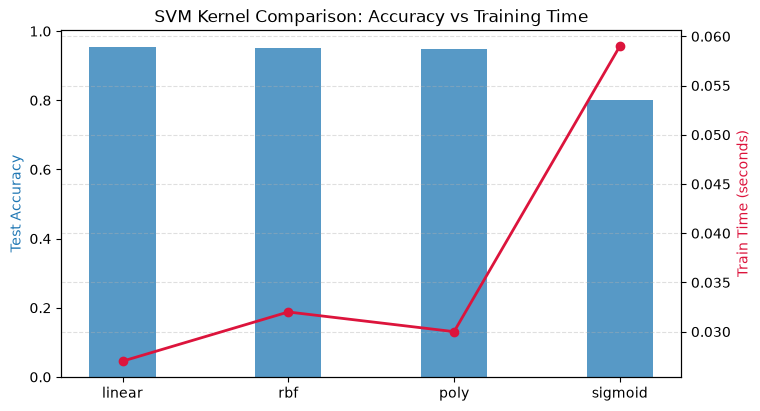

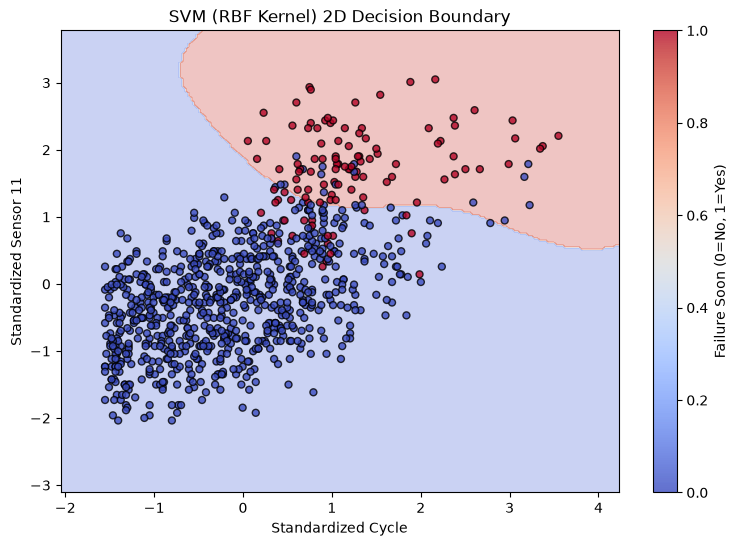

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report


cols = ["engine_id", "cycle", "setting_1", "setting_2", "setting_3"] + [f"sensor_{i}" for i in range(1, 22)]
df = pd.read_csv("../dataset/CMAPSSData/train_FD001.txt", sep=r"\s+", header=None, names=cols)

df["RUL"] = df.groupby("engine_id")["cycle"].transform("max") - df["cycle"]
df["failure_soon"] = (df["RUL"] <= 30).astype(int)

# Use balanced subsample for computationally efficient SVM evaluation
df_sample = df.sample(n=3500, random_state=42)

features = ["cycle", "sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_11", "sensor_12", "sensor_15"]
X = df_sample[features]
y = df_sample["failure_soon"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Feature Scaling is critical for Support Vector Machines
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. Compare different SVM kernels
kernels = ["linear", "rbf", "poly", "sigmoid"]
kernel_results = []

for k in kernels:
    start_time = time.time()
    svm = SVC(kernel=k, C=1.0, random_state=42)
    svm.fit(X_train_scaled, y_train)
    fit_time = time.time() - start_time
    
    y_pred = svm.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    kernel_results.append({"Kernel": k, "Accuracy": acc, "F1-Score": f1, "Train Time (s)": round(fit_time, 3)})

results_df = pd.DataFrame(kernel_results)
print("\nSVM Kernel Performance Comparison:")
print(results_df.to_string(index=False))

# Plot accuracy and training time comparison
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax2 = ax1.twinx()

bars = ax1.bar(results_df["Kernel"], results_df["Accuracy"], alpha=0.75, color="#1f77b4", width=0.4, label="Accuracy")
ax2.plot(results_df["Kernel"], results_df["Train Time (s)"], color="crimson", marker="o", linewidth=2, label="Train Time (s)")

ax1.set_ylabel("Test Accuracy", color="#1f77b4")
ax2.set_ylabel("Train Time (seconds)", color="crimson")
ax1.set_title("SVM Kernel Comparison: Accuracy vs Training Time")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# 2. Decision Boundary Visualization in 2D (cycle vs sensor_11)
X_2d = df_sample[["cycle", "sensor_11"]]
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

X2_train, X2_test, y2_train, y2_test = train_test_split(X_2d_scaled, y, test_size=0.25, random_state=42)

svm_rbf_2d = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm_rbf_2d.fit(X2_train, y2_train)

# Generate mesh grid
x_min, x_max = X_2d_scaled[:, 0].min() - 0.5, X_2d_scaled[:, 0].max() + 0.5
y_min, y_max = X_2d_scaled[:, 1].min() - 0.5, X_2d_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

Z = svm_rbf_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
scatter = plt.scatter(X2_test[:, 0], X2_test[:, 1], c=y2_test, cmap="coolwarm", edgecolor="k", s=25, alpha=0.8)
plt.xlabel("Standardized Cycle")
plt.ylabel("Standardized Sensor 11")
plt.title("SVM (RBF Kernel) 2D Decision Boundary")
plt.colorbar(scatter, label="Failure Soon (0=No, 1=Yes)")
plt.show()

print("Experiment 8 Completed Successfully")